# Evaluation Pipeline for VIPER Model

> **Note**: This notebook documents the evaluation procedure used to assess model performance on clinical variant prioritization.
> All aggregation and metric computation were performed in **Excel** using Power Query, VLOOKUP, and built-in functions.
> The results are then visualized using Python.

## Overview of Workflow

1. **Aggregate Inference Results**:
   - Input: Multiple `.xlsx` files (one per sample) from inference step
   - Process: Use Power Query to merge all samples, transform scores, rank variants within each sample
   - Output: `example_metadata.xlsx` — contains variant-level predictions with ranking

2. **Compute Performance Metrics**:
   - Overall recall of true positive variants
   - Number of candidate positive variants per sample
   - Top-k recall

3. **Visualize Results**:
   - Violin plot: distribution of positive variant counts across models
   - Line plot: Top-k recall curves for comparison

## Benchmark Models Evaluated

We compare **VIPER** against several representative baselines:

- **VIPER** (Ours): Fine-tuned Qwen3 with joint phenotype-genotype modeling
- **Xrare** : A machine learning method jointly modeling phenotypes and genetic evidence
  → [GitHub: liqg/xrare37-pub:2021](https://github.com/liqg/xrare37-pub)
- **Exomiser / PHIVE / PhenIX**: Integrated variant prioritization suite supporting multiple algorithms
  → [GitHub: exomiser/Exomiser (v14.1.0)](https://github.com/exomiser/Exomiser)
- **GeneT** :  a variant prioritization LLM fine-tuned across diverse rare genetic diseases
  → [Genetic Transformer](https://doi.org/10.1101/2024.07.18.24310666)

Handling of missing true causal variants:

- **Xrare** does not expose tunable parameters and, by design, only returns a fixed set of top-ranked candidates. For cases where the true causal variant was not included in Xrare’s output, we performed synthetic rank augmentation using a data-driven imputation strategy (see `augment_missing_gold_answers` function below). This approach preserves the empirical relationship between the number of candidates (`n_candidates`) and the observed rank of the gold-standard variant among samples where it was recovered.
- For **Exomiser**, as well as its internal prioritization modules **PHIVE** and **PhenIX**, we adjusted configuration parameters to maximize recall of potentially relevant variants: specifically, we set `analysisMode = FULL` and configured `numGenes = 0` with `maxFrequency = 2.0` to relax filtering thresholds and retain missing true causal variants that might otherwise be excluded.

> **Note**: For Xrare, Exomiser, PHIVE, PhenIX and GeneT, we followed their official documentation to run inference on the same IEI cohort (n=205).
> Deployment, preprocessing, and execution scripts are not provided here.

In [3]:
import pandas as pd
import numpy as np
from sklearn.linear_model import QuantileRegressor
from scipy.interpolate import interp1d

def augment_missing_gold_answers(
    input_csv: str,
    output_csv: str,
    N_TARGET: int = None,
    target_quantile: float = 0.9,
    random_seed: int = 42
):
    """
    Impute plausible ranks for samples where the gold-standard variant was not returned by Xrare.
    
    This function augments the candidate list size to a common target (N_TARGET) and assigns
    a synthetic rank to the missing causal variant based on the empirical rank distribution
    learned from successfully recovered cases.
    
    Parameters:
    ----------
    input_csv : str
        Path to input CSV with columns: 'rank', 'n_candidates', 'contains_gold'.
        - 'rank': Rank of the gold-standard variant (NaN or > n_candidates if missing).
        - 'n_candidates': Total number of variants returned by the tool.
        - 'contains_gold': Boolean indicating whether the gold variant is present.
    
    output_csv : str
        Path to save the augmented results.
    
    N_TARGET : int, optional
        Target number of candidates after augmentation. If None, inferred as the
        `target_quantile`-th percentile of 'n_candidates'.
    
    target_quantile : float, default=0.9
        Quantile used to determine N_TARGET if not provided.
    
    random_seed : int, default=42
        Random seed for reproducibility.
    
    Returns:
    -------
    pd.DataFrame
        DataFrame with new columns: 'rank_aug' (imputed rank) and 'n_candidates_aug'.
    """
    np.random.seed(random_seed)
    df = pd.read_csv(input_csv)

    # Validate required columns
    required_cols = {'rank', 'n_candidates', 'contains_gold'}
    if not required_cols.issubset(df.columns):
        raise ValueError(f"Input must contain columns: {required_cols}")
    
    df['contains_gold'] = df['contains_gold'].astype(bool)

    # Determine N_TARGET
    if N_TARGET is None:
        N_TARGET = int(df['n_candidates'].quantile(target_quantile))
        print(f"Using {target_quantile*100:.0f}th percentile as N_TARGET: {N_TARGET}")

    if N_TARGET <= df['n_candidates'].max():
        print(f"Warning: N_TARGET ({N_TARGET}) ≤ max(n_candidates). Consider increasing.")

    # Filter observed (gold-containing) samples for modeling
    df_obs = df[df['contains_gold']].copy()
    if len(df_obs) == 0:
        raise ValueError("No samples contain the gold-standard variant — cannot model rank distribution.")

    # Fit quantile regression models at multiple quantiles
    print("Fitting quantile regression models...")
    X_obs = df_obs['n_candidates'].values.reshape(-1, 1)
    y_obs = df_obs['rank'].values
    quantiles = [0.1, 0.25, 0.5, 0.75, 0.9]
    quantile_models = {}

    for q in quantiles:
        reg = QuantileRegressor(quantile=q, alpha=0, solver='highs')
        reg.fit(X_obs, y_obs)
        quantile_models[q] = reg

    def augment_row(row):
        if row['contains_gold']:
            return row['rank'], row['n_candidates']
        
        original_n = row['n_candidates']
        if N_TARGET <= original_n:
            # Cannot insert gold variant into an already full or oversized list
            return original_n + 1, N_TARGET

        # Predict rank distribution at original_n
        x_pred = np.array([[original_n]])
        pred_ranks = np.array([quantile_models[q].predict(x_pred)[0] for q in quantiles])
        pred_ranks = np.clip(pred_ranks, original_n + 1, N_TARGET)

        # Interpolate to sample continuous rank
        pred_func = interp1d(quantiles, pred_ranks, bounds_error=False, fill_value="extrapolate")
        sampled_q = np.random.uniform(0.1, 0.9)
        continuous_rank = pred_func(sampled_q).item()
        continuous_rank += np.random.normal(0, 0.3)  # Add mild noise for realism
        continuous_rank = np.clip(continuous_rank, original_n + 1, N_TARGET)

        final_rank = int(round(continuous_rank))
        return final_rank, N_TARGET

    # Apply augmentation
    print("Augmenting missing gold-standard ranks...")
    df[['rank_aug', 'n_candidates_aug']] = df.apply(augment_row, axis=1, result_type='expand')
    df.to_csv(output_csv, index=False)

    print(f"Done. Saved to: {output_csv}")
    print(f"Total samples: {len(df)}")
    print(f"Missing gold: {len(df[~df['contains_gold']])}")
    print(f"N_TARGET: {N_TARGET}")

    return df

## Step 1: Data Aggregation (Performed in Excel)

We aggregated the inference results from individual `.xlsx` files into a unified dataset using **Power Query** in Excel:

1. Load all `.xlsx` files into a single table
2. Transform score:
   - If label = `"positive"` → use raw `score`
   - If label = `"negative"` → use `1 - score` (i.e., probability of being positive)
3. Rank variants within each sample by transformed score (descending)
4. Add row index (`rank`) per sample


In [4]:
import pandas as pd

# Load the aggregated metadata file (example)
metadata_df = pd.read_excel("example_metadata.xlsx")
metadata_df.head()

,Source.Name,cpra,gene symbol,zygosity,predict,AdjustedScore,rank,transcript,dna change,protein change,...,dbscSnv_ADA,PhyloP Vertebrates,PhyloP Placental Mammals,GERP++,associated diseases,1000G,GnomAD,GnomAD-EAS,ACMG evidence items,pathogenicity assessment
0,53,chr5-169111233-C-T,DOCK2,Hom,positive,0.621330,1,NM_004946.3,c.640C>T,p.Arg214Trp,...,NaN,3.149,1.026,5.430,"[{""description"": ""The DOCK2 gene encodes a hem...",0.00659,0.000605,0.000000,"BS2,PP2,BP6",Likely Benign
1,53,chr21-46951496-C-T,SLC19A1,Hom,negative,0.469190,2,NM_194255.4,c.756G>A,p.Ala252Ala,...,NaN,NaN,NaN,1.070,"[{""description"": ""The SLC19A1 gene encodes red...",NaN,NaN,NaN,"PM2,BP7",Uncertain Significance
2,53,chr12-98927992-C-T,TMPO,Het,negative,0.409625,3,NM_001032283.3,c.565+2376C>T,NaN,...,NaN,3.599,1.026,5.960,"[{""description"": NaN, ""genemap"": NaN}]",0.00100,0.000287,0.000000,BP4,Uncertain Significance
3,53,chr2-113890284-G-A,IL1RN,Het,negative,0.354523,4,NM_173842.3,c.370G>A,p.Ala124Thr,...,NaN,-0.103,-0.412,-0.802,"[{""description"": ""IL1 receptor antagonist (IL1...",0.00479,0.001051,0.011538,"BS1,BS2_Supporting,BP4",Likely Benign
4,53,chr6-144507978-T-C,STX11,Het,negative,0.296964,5,NM_003764.4,c.214T>C,p.Phe72Leu,...,NaN,7.797,1.138,5.990,"[{""description"": ""The STX11 gene encodes synta...",NaN,NaN,NaN,PM2,Uncertain Significance


## Step 2: Compute Performance Metrics

All metrics were computed in Excel/WPS using formulas. Below are the definitions and examples.

### 1. Overall Recall of True Positive Variants

> Definition: Fraction of true positive variants that are predicted as `positive`.

$$
\text{Recall} = \frac{\sum_{v \in \mathcal{P}} \mathbb{I}(\text{predict}(v) = \text{positive})}{|\mathcal{P}|}
$$

Where:
- $\mathcal{P}$: set of all true positive variants across all samples
- $\mathbb{I}(\cdot)$: indicator function

### 2. Candidate Variant Count

> Definition: Total number of variants predicted as `positive` per sample (or overall).

$$
\text{Candidate Count} = \sum_{v} \mathbb{I}(\text{predict}(v) = \text{positive})
$$

### 3. Top-k Recall

In the IEI cohort, some patients harbor **multiple causal variants**. To avoid underestimating recall due to rank inflation among true positives, we compute an **adjusted rank** for each true positive variant:

$$
r^{\text{adj}}_i(v) = r_i(v) - \left| \left\{ u \in \mathcal{P}_i \,\middle|\, r_i(u) < r_i(v) \right\} \right|
$$

where:
- $ r_i(v) $: original rank of variant $ v $ in sample $ i $
- $ \mathcal{P}_i $: set of true positive variants in sample $ i $

The adjusted rank represents the **order in which this causal variant is recovered** among all causal variants in the same sample.

Then, Top-k recall is defined as:

$$
\text{Top-}k \text{ Recall} =
\frac{
  \sum_{i=1}^{N} \sum_{v \in \mathcal{P}_i}
  \mathbb{I}\left( r^{\text{adj}}_i(v) \leq k \right)
}{
  \sum_{i=1}^{N} |\mathcal{P}_i|
}
$$

This ensures fair evaluation when multiple pathogenic variants exist per case.


In [5]:
# Load the metrics summary for VIPER on IEI cohort
results_df = pd.read_excel("example_results_IEI.xlsx")
results_df

,Metrics,Base,VIPER,GeneT,Xrare,Exomiser,Phive,Phenix
0,Overall Recall,0.988372,0.879845,0.906977,\,\,\,\
1,Avg.Candidate Counts,183.872146,16.283105,23.014634,110.985366,1353.770732,2855.35122,2009.531707
2,Top-1,0.031008,0.697674,0.515504,0.255814,0.453488,0.294574,0.507752
3,Top-5,0.205426,0.848837,0.802326,0.53876,0.751938,0.53876,0.72093
4,Top-10,0.325581,0.926357,0.860465,0.693798,0.813953,0.651163,0.763566
5,Top-20,0.488372,0.957364,0.903101,0.75969,0.852713,0.70155,0.844961
6,Top-50,0.651163,0.988372,0.968992,0.806202,0.914729,0.844961,0.934109
7,Top-80,0.782946,0.996124,0.976744,0.887597,0.918605,0.875969,0.957364
8,Top-100,0.833333,1.000000,0.980620,0.94186,0.922481,0.887597,0.957364
9,Top-200,0.968992,1.000000,0.988372,0.996124,0.945736,0.918605,0.968992


## Step 3: Visualization

Final results (Including all models) are stored in `combined_results_IEI.xlsx`:
- **Sheet1**: For violin plot — `model`, `positive_variant_count`
- **Sheet2**: For Top-k recall curve — `k`, `recall` for each model

We now load these sheets and generate plots.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
def plot_violin(sheet1_df, ref_model_idx=1, output_prefix="violin_plot", save=False):
    """
    Plot violin plot from Sheet1 of combined_results_IEI.xlsx.

    Parameters:
    - sheet1_df: pd.DataFrame, wide format. Columns = model names, Rows = samples.
    - ref_model_idx: int, index of reference model for statistical comparison (default: 1 = VIPER)
    - output_prefix: str, prefix for saved figures
    """
    # Validate: all values must be positive integers
    if (sheet1_df <= 0).any().any():
        raise ValueError("All values in Sheet1 must be positive (positive variant counts).")

    data_log = np.log10(sheet1_df.astype(float))

    # Normality test
    normality_results = {}
    for col in data_log.columns:
        k2, p = stats.normaltest(data_log[col])
        normality_results[col] = {'stat': k2, 'p': p}
        print(f"Normality test for {col}: Stat={k2:.3f}, P-value={p:.3e}")

    # Plot
    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["pdf.fonttype"] = 42
    fig, ax = plt.subplots(figsize=(8, 6), facecolor='white')

    sns.violinplot(data=data_log, palette="colorblind", alpha=0.7, ax=ax)
    ax.set_facecolor('white')

    # Spines
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_color('black')

    # Ticks
    ax.tick_params(axis='x', which='both', direction='out', length=4, width=1.0,
                   color='black', labelcolor='black', labelsize=14, bottom=True, top=False)
    ax.tick_params(axis='y', which='both', direction='out', length=4, width=1.0,
                   color='black', labelcolor='black', labelsize=14, left=True, right=False)

    ax.set_ylabel('Log(Positive Variant Calls)', fontsize=16, color='black')
    ax.set_xlabel('Models', fontsize=16, color='black')
    ax.grid(False)

    # Statistical comparison vs reference model
    cols = list(data_log.columns)
    ref_col = cols[ref_model_idx]
    y_max = data_log.values.max()
    y_range = data_log.values.max() - data_log.values.min()
    y_offset_step = y_range * 0.08
    comparison_count = 0

    for i, col in enumerate(cols):
        if i == ref_model_idx:
            continue

        if normality_results[col]['p'] > 0.05 and normality_results[ref_col]['p'] > 0.05:
            _, p_val = stats.ttest_rel(data_log[col], data_log[ref_col])
            test_type = 'Paired t-test'
        else:
            _, p_val = stats.wilcoxon(data_log[col], data_log[ref_col])
            test_type = 'Wilcoxon signed-rank test'

        print(f"{col} vs {ref_col}: {test_type}, P = {p_val:.3e}")

        if p_val >= 0.05:
            continue

        sig_symbol = '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*'
        y_pos = y_max + (comparison_count + 1) * y_offset_step
        comparison_count += 1

        x1, x2 = i, ref_model_idx
        ax.plot([x1, x1, x2, x2], [y_pos - y_offset_step/4, y_pos, y_pos, y_pos - y_offset_step/4],
                lw=1.2, color='black')
        ax.text((x1 + x2)/2, y_pos + y_offset_step/6, sig_symbol,
                ha='center', va='bottom', fontsize=12, fontweight='bold')

    plt.tight_layout()
    if save:
        for ext in ['png', 'pdf', 'svg']:
            plt.savefig(f"{output_prefix}.{ext}", dpi=300, bbox_inches='tight')
    plt.show()

def plot_topk(sheet2_df, suffix="Pathogenic", output_prefix="topk_recall", save=False):
    """
    Plot Top-k recall curve from Sheet2 of combined_results_IEI.xlsx.

    Parameters:
    - sheet2_df: pd.DataFrame, index = k values (e.g., 1,5,10,50), columns = model names
    - suffix: str, appended to y-label
    - output_prefix: str, prefix for saved figures
    """
    # Ensure index is numeric
    sheet2_df.index = pd.to_numeric(sheet2_df.index)

    plt.figure(figsize=(8, 6), facecolor='white')
    plt.rcParams["font.family"] = "Arial"
    plt.rcParams["pdf.fonttype"] = 42

    model_names = sheet2_df.columns.tolist()
    colors = sns.color_palette("colorblind", n_colors=len(model_names))

    for i, model in enumerate(model_names):
        k_vals = list(range(1, sheet2_df.shape[0] + 1))
        recall_vals = sheet2_df[model].values
        plt.plot(k_vals, recall_vals, label=model, lw=1.5, color=colors[i])

    ax = plt.gca()
    ax.set_facecolor('white')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']:
        ax.spines[spine].set_color('black')

    ax.tick_params(axis='x', colors='black', bottom=True, labelsize=15)
    ax.tick_params(axis='y', colors='black', left=True, labelsize=15)

    plt.xlabel('Top-k', fontsize=17)
    plt.ylabel(f'Recall Rate - {suffix}', fontsize=17)
    plt.ylim([0,1.02])
    plt.legend(fontsize=15)
    plt.grid(False)
    plt.tight_layout()
    if save:
        for ext in ['png', 'pdf', 'svg']:
            plt.savefig(f"{output_prefix}.{ext}", bbox_inches='tight')
    plt.show()

Normality test for Original(input): Stat=1649.037, P-value=0.000e+00
Normality test for VIPER: Stat=4.343, P-value=1.140e-01
Normality test for GeneT: Stat=13.717, P-value=1.050e-03
Normality test for Xrare: Stat=33.454, P-value=5.441e-08
Normality test for PHIVE: Stat=297.757, P-value=2.202e-65
Normality test for Exomiser: Stat=114.970, P-value=1.083e-25
Normality test for Phenix: Stat=282.121, P-value=5.472e-62
Original(input) vs VIPER: Wilcoxon signed-rank test, P = 2.176e-35
GeneT vs VIPER: Wilcoxon signed-rank test, P = 1.495e-14
Xrare vs VIPER: Wilcoxon signed-rank test, P = 1.306e-29
PHIVE vs VIPER: Wilcoxon signed-rank test, P = 2.176e-35
Exomiser vs VIPER: Wilcoxon signed-rank test, P = 2.176e-35
Phenix vs VIPER: Wilcoxon signed-rank test, P = 2.176e-35


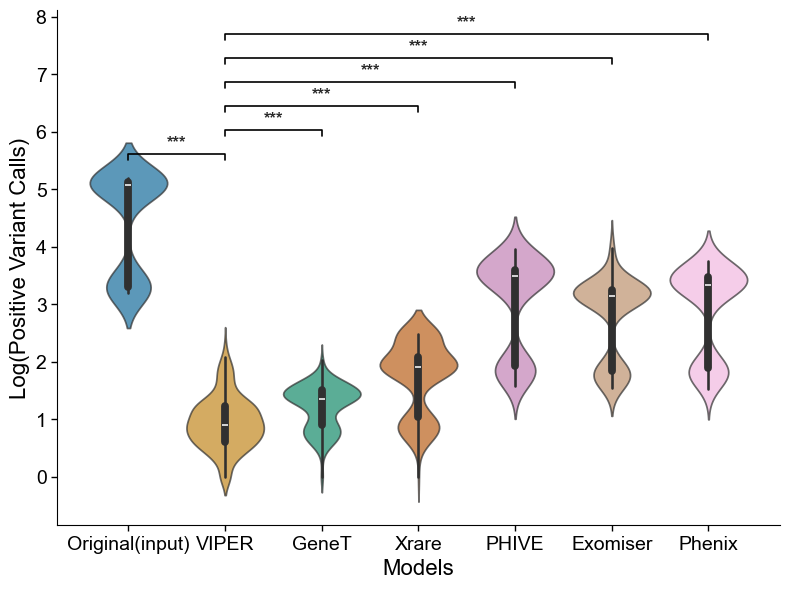

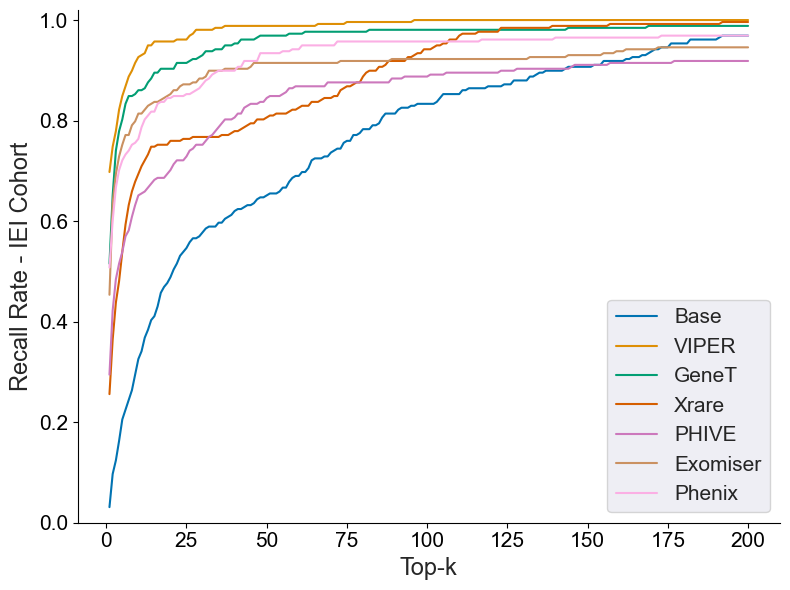

In [11]:
# Load the real Excel file
file_path_IEI = "combined_results_IEI.xlsx"

# Sheet1: positive variant counts per sample per model
sheet1 = pd.read_excel(file_path_IEI, sheet_name=0)
plot_violin(sheet1, ref_model_idx=1, output_prefix="violin_IEI", save=True)

# Sheet2: Top-k recall (k as row index)
sheet2 = pd.read_excel(file_path_IEI, sheet_name=1)
plot_topk(sheet2, suffix="IEI Cohort", output_prefix="topk_IEI", save=True)

## Evaluation on Challenging IEI Subsets

We curated **five biologically challenging inheritance or phenotypic scenarios** from the IEI cohort to stress-test model robustness. These include cases with:

1. **Same causal gene, heterogeneous phenotypes** (`same_gene_het_pheno`)
2. **CVID patients with distinct pathogenic variants** (`cvid_distinct_var`)
3. **Identical pathogenic variant, divergent clinical presentations** (`same_var_het_pheno`)
4. **Compound heterozygous inheritance** (`comp_het`)
5. **Incomplete penetrance** (`incomp_pen`)

> **Note**: The first four categories are explicitly encoded as boolean columns in **Sheet3** of `combined_results_IEI.xlsx` and visualized below.
> The fifth category (**incomplete penetrance**) is evaluated separately and reported in **Supplementary Table S4**, but not included in the subset plots due to limited sample size and differences in assessment criteria (see Methods).

In [8]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from upsetplot import plot

def generate_upset_plot(df_or_path, figsize=(15, 6), show_counts=True, save=False):
    """
    Generate publication-quality UpSet plot for challenge subsets.

    Parameters:
        df_or_path: str or pd.DataFrame
        figsize: tuple
        show_counts: bool
        save: bool, whether to save figures
    """
    if isinstance(df_or_path, str):
        df = pd.read_excel(df_or_path, sheet_name=2)  # Sheet3 = index 2
    else:
        df = df_or_path.copy()

    bool_cols = ['same_gene_het_pheno', 'cvid_distinct_var', 'same_var_het_pheno', 'comp_het', 'incomp_pen']
    for col in bool_cols:
        df[col] = df[col].astype(bool)

    subset_counts = df[bool_cols].value_counts()
    print("Subset counts:")
    print(subset_counts)

    plt.figure(figsize=figsize)
    # Note: 'facecolor' is not a valid param for upsetplot.plot → remove it
    ax_dict = plot(subset_counts, show_counts=show_counts, sort_by='degree')

    # Style axes
    ax_dict['totals'].grid(False)
    ax_dict['intersections'].grid(True, axis='y', linestyle='--', alpha=0.5)

    if save:
        for ext in ['png', 'svg', 'pdf']:
            plt.savefig(f"upset_challenge_subsets.{ext}", dpi=300, bbox_inches='tight')
    plt.show()

def plot_violin_2(
    df,
    ref_model,
    title_name,
    output_pdf="ranking_violin_top10acc.pdf",
    clip_percentile=95,
    save=False
):
    """
    Plot ranking distribution (strip) + Top-10 recall (bar) for challenge subsets.
    """
    # plt.rcParams["font.family"] = "Arial"
    # plt.rcParams["pdf.fonttype"] = 42

    model_names = df.columns.tolist()
    if ref_model not in model_names:
        raise ValueError(f"Reference model '{ref_model}' not found.")
    ref_idx = model_names.index(ref_model)

    # --- Top-10 Accuracy ---
    top10_acc = (df <= 10).mean(axis=0)

    # --- Normality & Significance ---
    normality = {}
    for col in model_names:
        sample = df[col].dropna()
        if len(sample) > 5000:
            sample = sample.sample(n=min(5000, len(sample)), random_state=42)
        try:
            _, p_norm = stats.shapiro(sample)
        except Exception as e:
            print(f"Shapiro failed for {col}: {e}. Assuming non-normal.")
            p_norm = 0.0
        normality[col] = p_norm

    pvals, test_methods, results = [], [], []
    for col in model_names:
        if col == ref_model:
            p_val, test_type = 1.0, "Reference"
        else:
            is_ref_norm = normality[ref_model] > 0.05
            is_col_norm = normality[col] > 0.05
            if is_ref_norm and is_col_norm:
                _, p_val = stats.ttest_rel(df[ref_model], df[col], nan_policy='omit')
                test_type = 'Paired t-test'
            else:
                try:
                    _, p_val = stats.wilcoxon(df[ref_model], df[col])
                except ValueError:
                    p_val = 1.0
                test_type = 'Wilcoxon signed-rank test'
        pvals.append(p_val)
        test_methods.append(test_type)
        results.append({'Model': col, 'Top10_Acc': top10_acc[col], 'Raw_p': p_val})

    # FDR correction
    _, pvals_fdr, _, _ = multipletests(pvals, method='fdr_bh')
    for i, row in enumerate(results):
        row['FDR_p'] = pvals_fdr[i]
        row['Sig_Symbol'] = '***' if pvals_fdr[i] < 0.001 else '**' if pvals_fdr[i] < 0.01 else '*' if pvals_fdr[i] < 0.05 else 'ns'

    # Save CSV
    if save:
        output_csv = os.path.splitext(output_pdf)[0] + ".csv"
        pd.DataFrame(results).to_csv(output_csv, index=False)
        print(f"Significance results saved to {output_csv}")

    # Plotting Data (clipped for visualization only)
    df_plot = df.copy()
    for col in df_plot.columns:
        upper = df[col].quantile(clip_percentile / 100)
        df_plot[col] = df_plot[col].where(df_plot[col] <= upper)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

    # Strip plot (ranking)
    sns.stripplot(data=df_plot, ax=ax1, palette="colorblind", size=5, alpha=0.7, edgecolor='black', linewidth=0.5)
    ax1.set_ylabel("Rank", fontsize=16)
    ax1.set_xlabel("")
    ax1.set_title(title_name)
    ax1.tick_params(axis='x', bottom=False, labelsize=14)
    ax1.tick_params(axis='y', left=True, labelsize=14)
    ax1.set_facecolor("white")
    for spine in ['top', 'right']: ax1.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']: ax1.spines[spine].set_color('black')

    # Bar plot (Top-10 recall)
    colors = sns.color_palette("colorblind", n_colors=len(model_names))
    bars = ax2.bar(model_names, [top10_acc[m] for m in model_names], color=colors, alpha=0.8, width=0.6)
    ax2.set_ylabel("Top-10 Recall", fontsize=16)
    ax2.set_ylim(0, 1.0)
    ax2.set_xlabel("Model", fontsize=16)
    ax2.tick_params(axis='x', labelsize=14)
    ax2.tick_params(axis='y', labelsize=14)
    ax2.set_facecolor("white")
    for spine in ['top', 'right']: ax2.spines[spine].set_visible(False)
    for spine in ['bottom', 'left']: ax2.spines[spine].set_color('black')

    # Add value labels on bars
    for bar, acc in zip(bars, [top10_acc[m] for m in model_names]):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f"{acc:.2f}", ha='center', va='bottom', fontsize=12)

    # Significance annotations (on ax1)
    y_max = df_plot.max().max()
    if pd.isna(y_max): y_max = df.max().max()
    y_offset_step = y_max * 0.12
    comparison_count = 0

    for i, col in enumerate(model_names):
        if col == ref_model: continue
        sig = results[i]['Sig_Symbol']

        y_pos = y_max + (comparison_count + 1) * y_offset_step
        comparison_count += 1
        x1, x2 = i, ref_idx
        ax1.plot([x1, x1, x2, x2],
                 [y_pos - y_offset_step/8, y_pos, y_pos, y_pos - y_offset_step/8],
                 lw=1, color='black')
        ax1.text((x1 + x2)/2, y_pos + y_offset_step/10, sig,
                 ha='center', va='bottom', fontsize=12, fontweight='bold')

    plt.tight_layout(h_pad=0.5)
    if save:
        for ext in ['png', 'pdf', 'svg']:
            plt.savefig(output_pdf.replace('.pdf', f'.{ext}'), bbox_inches='tight', dpi=300)
        print(f"Figure saved to {output_pdf.replace('.pdf', '.*')}")
    plt.show()

Subset counts:
same_gene_het_pheno  cvid_distinct_var  same_var_het_pheno  comp_het  incomp_pen
True                 True               False               False     False         62
False                True               False               False     False         41
True                 False              False               False     False         41
False                True               False               True      False         16
                     False              False               False     False         15
                                                            True      False         15
True                 True               True                False     False          5
                     False              True                False     False          3
False                True               True                False     False          3
True                 False              False               False     True           2
False                False        

<Figure size 1500x600 with 0 Axes>

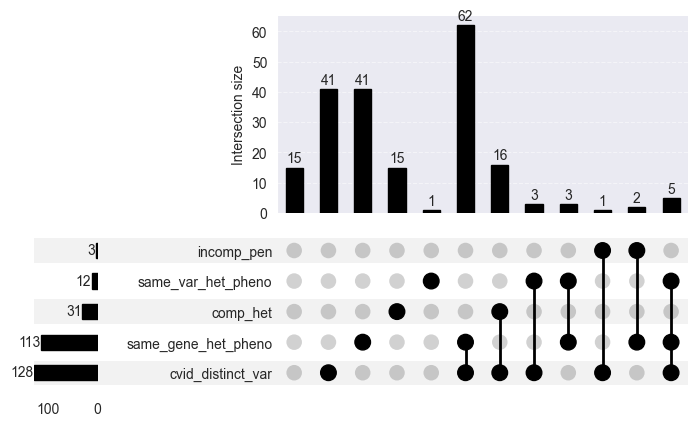

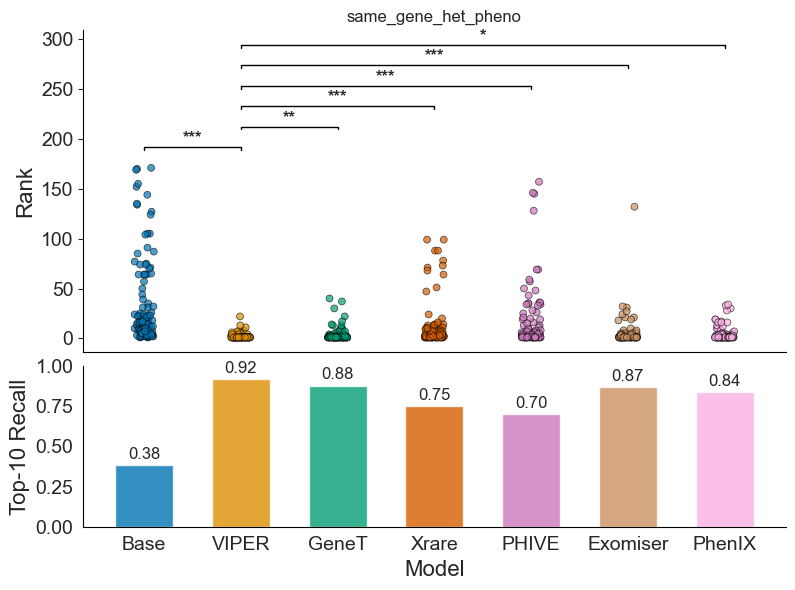

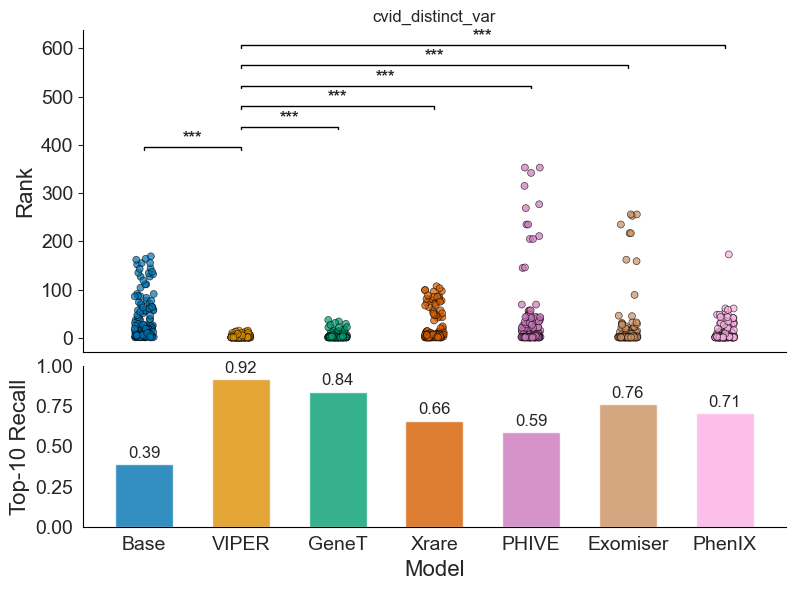

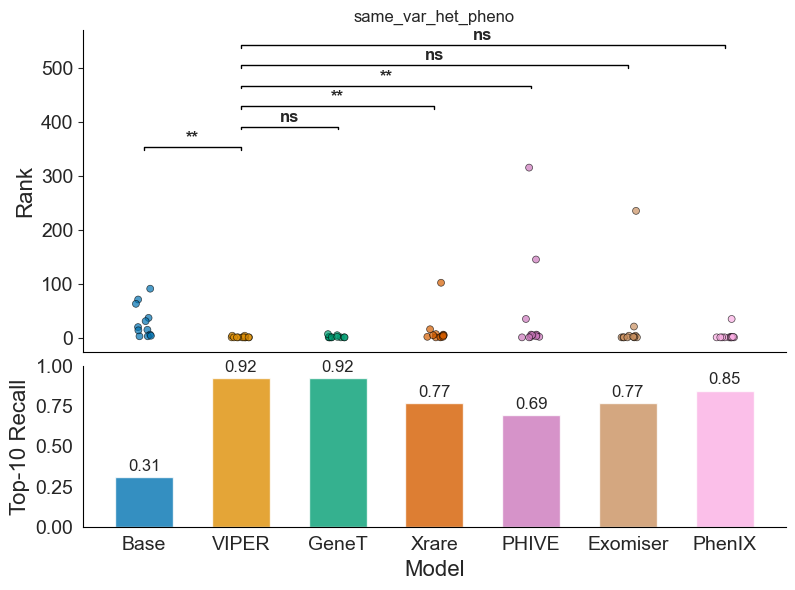

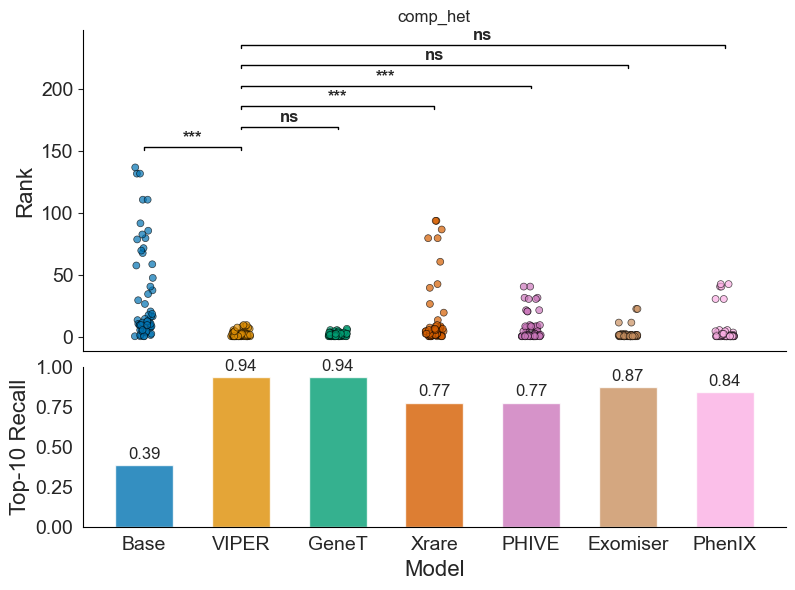

In [9]:
generate_upset_plot(file_path_IEI, save=False)
subset_names = ["same_gene_het_pheno", "cvid_distinct_var", "same_var_het_pheno", "comp_het"]
for i, name in enumerate(subset_names):
    sheet_idx = 3 + i  # Sheet4 = idx 3, ..., Sheet7 = idx 6
    try:
        df_subset = pd.read_excel(file_path_IEI, sheet_name=sheet_idx)
        plot_violin_2(
            df=df_subset,
            ref_model="VIPER",
            title_name=name,
            output_pdf=f"challenge_{name}_ranking.pdf",
            save=False
        )
    except Exception as e:
        print(f"Skipping {name}: {e}")